# 05 · Unsupervised Learning + Anomaly Detection — FinSight AI
**Phase 6 · Subject: ML** (clustering is also DMW's cluster-analysis component) · KDD steps 5–6

| RQ | Question |
|---|---|
| **RQ5** | Can unsupervised clustering recover risk groupings without labels? |
| **RQ6** | How well do Isolation Forest, One-class SVM and an Autoencoder trained **only on legitimate data** detect fraud, overall and per scenario? |

### Protocol (Plan §7.4–7.5)
| Item | Choice |
|---|---|
| Data | v1.1 master (10,000 rows), same 60/20/20 stratified split as Phase 5 |
| Features | Exp B (44 encoded columns) and Exp C (63), signed-log1p → StandardScaler, one-hot categoricals; leakage/ID blacklist enforced |
| Clustering | all 10,000 rows, **labels never used to fit**; labels attached afterwards (fraud %, scenario mix, ARI/NMI) |
| K selection | K = 2..8; lowest Davies–Bouldin among K within 0.005 of the best silhouette (D-026) |
| DBSCAN | min_samples = 10, ε = knee of the 10-distance curve |
| Detectors | fitted on **LEGITIMATE training rows only** (4,920 rows); no fraud, no BORDERLINE |
| Thresholds | 95th / 99th percentile of scores on the 1,640 **legitimate validation** rows (D-025) |
| Metrics | test PR-AUC, ROC-AUC, recall at 1% FPR, precision/recall at p95, BORDERLINE flag rate |
| Serving | Autoencoder exported PyTorch → ONNX, checked for parity (≤ 1e-5) |

Everything here is computed by `finsight.ml.unsupervised` (pipeline stage `unsupervised`); this notebook only displays it.

In [1]:
import warnings, json; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import display, Image
from finsight import viz, config
from finsight.eda import load_master
from finsight.ml import unsupervised as U, unsupervised_figures as F, anomaly as A
from finsight.ml.splits import stratified_split
viz.apply_style()
pd.set_option("display.width", 200, "display.max_columns", 30)
R = config.REPORTS_DIR
summary = json.loads((R / "unsupervised_summary.json").read_text())
m = load_master("v1_1"); sp = stratified_split(m)
cl = U.run_clustering(m)          # deterministic (seed 42): same numbers as the pipeline run
an = U.run_anomaly(m, sp)
te = m.iloc[sp.test]; y_te = te["is_fraud"].to_numpy()
print("split", sp.sizes(), "| legit train rows:", summary["anomaly"]["train_rows_legit"],
      "| legit val (reference) rows:", summary["anomaly"]["reference_rows_legit_val"])

split {'train': 6000, 'val': 2000, 'test': 2000} | legit train rows: 4920 | legit val (reference) rows: 1640


## 1 · RQ5: clustering — how many clusters, and how strong is the structure?

silhouette        davies_bouldin       
exp          B      C              B      C
k                                          
2        0.126  0.161          3.133  3.547
3        0.121  0.156          2.777  2.673
4        0.088  0.158          2.770  2.372
5        0.077  0.107          2.357  2.427
6        0.085  0.097          2.306  2.417
7        0.092  0.096          2.079  2.082
8        0.095  0.097          2.033  2.114

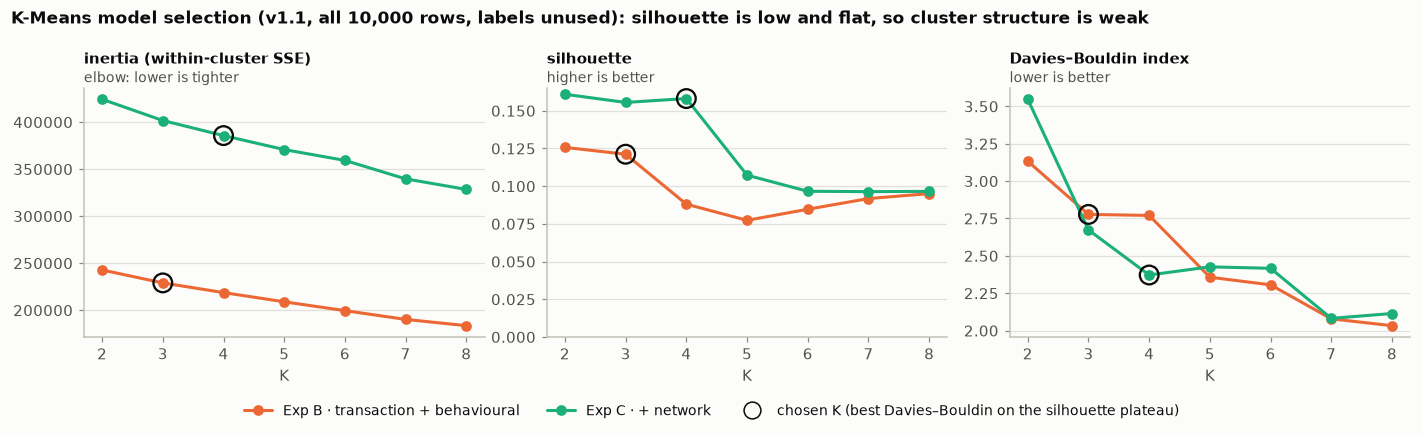

In [2]:
chosen = {e: summary["clustering"][e]["k"] for e in ("B", "C")}
F.fig_kmeans_selection(cl["sweeps"], chosen);
display(cl["sweeps"].pivot(index="k", columns="exp", values=["silhouette", "davies_bouldin"]).round(3))

- **Silhouette is low everywhere (≤ 0.16)**: transactions don't form well-separated blobs. Most of the data is one large, continuous cloud of normal behaviour.
- Silhouette is **flat** across K = 2–4 for Exp C (0.156–0.161), so it alone cannot choose K. Davies–Bouldin falls clearly from K = 2 (3.55) to K = 4 (2.37), so the combined rule picks **K = 4 for Exp C** and **K = 3 for Exp B**.
- Exp C (with network features) has a **higher** silhouette than Exp B at every K up to 5. The injected graph structure gives the clusters more to separate on.

,B,C
K,3.000,4.000
silhouette,0.121,0.158
Davies–Bouldin,2.777,2.372
ARI vs risk_label,0.302,0.473
NMI vs risk_label,0.188,0.271
flag fraud-heavy clusters: precision,0.408,0.431
flag fraud-heavy clusters: recall,0.677,0.857


,cluster,n,fraud_rate,share_BORDERLINE,share_FRAUDULENT,share_LEGITIMATE,top_scenario,exp,method
3,0,170,0.524,0.247,0.524,0.229,S3 rapid burst,C,kmeans
4,1,7320,0.026,0.011,0.026,0.962,S2 high value spike,C,kmeans
5,2,2187,0.401,0.149,0.401,0.450,S7 layering network,C,kmeans
6,3,323,0.588,0.000,0.588,0.412,S9 fraud ring hub,C,kmeans


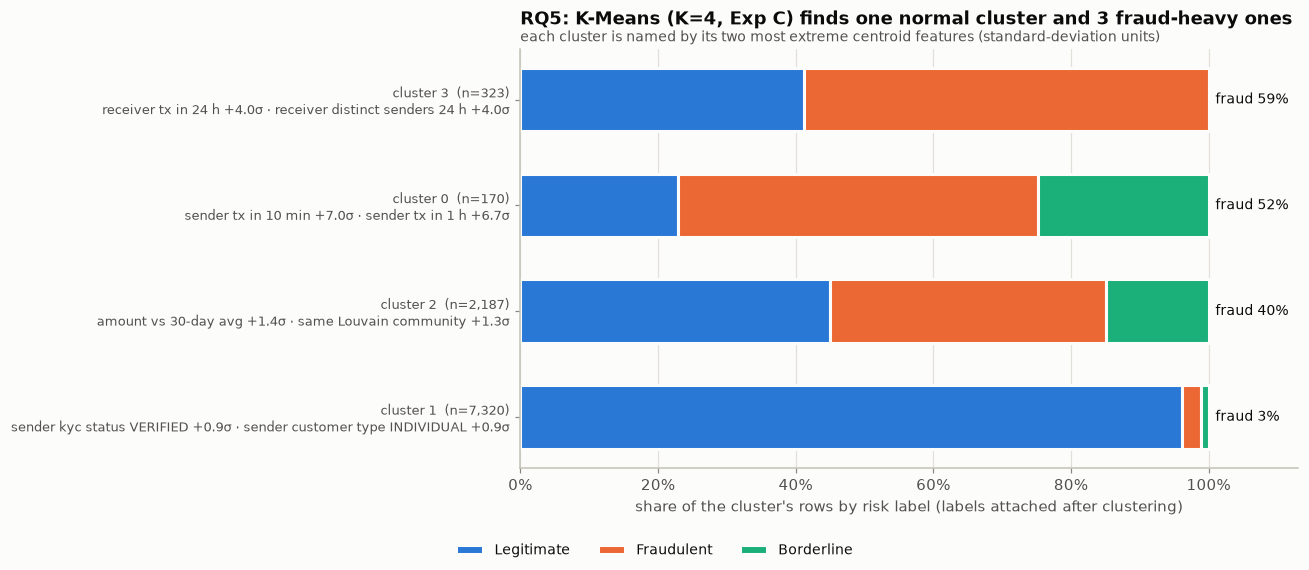

In [3]:
S = summary["clustering"]
display(pd.DataFrame({e: {"K": S[e]["k"], "silhouette": S[e]["silhouette"], "Davies–Bouldin": S[e]["davies_bouldin"],
                          "ARI vs risk_label": S[e]["kmeans_vs_label"]["ari"], "NMI vs risk_label": S[e]["kmeans_vs_label"]["nmi"],
                          "flag fraud-heavy clusters: precision": S[e]["flag_high_fraud_clusters"]["precision"],
                          "flag fraud-heavy clusters: recall": S[e]["flag_high_fraud_clusters"]["recall"]} for e in ("B", "C")}).round(3))
F.fig_cluster_composition(cl["clusters"], S["C"]["profile"]);
display(cl["clusters"].query("exp == 'C'").round(3))

**What the four Exp C clusters are** (named from their centroids, in standard-deviation units):

| Cluster | Size | Fraud | Defined by | Matches scenario |
|---|---|---|---|---|
| 1 | 7,320 | **3%** | nothing extreme (verified individual UPI users) | normal traffic, but it also hides 55% of S2 high-value-spike fraud and 39% of S6 structuring |
| 2 | 2,187 | **40%** | amount ≫ 30-day average, sender and receiver in the same Louvain community, high forward ratio | most other fraud: S7 layering (196 of 200), S8 mules, S4, S5, S10, S11 |
| 0 | 170 | **52%** | sender made ~7σ more transactions in the last 10 min / 1 h | S3 rapid burst |
| 3 | 323 | **59%** | receiver got ~4σ more transactions and distinct senders in 24 h; high PageRank | S9 fraud-ring hub (fan-in) |

**Answer to RQ5:** partly. Without seeing a single label, K-Means separates normal traffic (3% fraud) from three **interpretable risk groups**, each matching a fraud mechanism (velocity bursts, fan-in hubs, unusual-amount community flows). Agreement with the 3-class label is moderate (**ARI 0.47** for Exp C vs 0.30 for Exp B). If an analyst simply reviewed every row in the three risk clusters, they would catch **86% of fraud at 43% precision**, about 3× the 13.5% base rate, with no training labels at all. The clusters are mixed, though: 41–60% of the rows in each risk cluster are legitimate or BORDERLINE, and the frauds designed to blend in (S2, S6) mostly stay in the normal cluster. Clustering is useful for **triage and explanation**, not as a classifier.

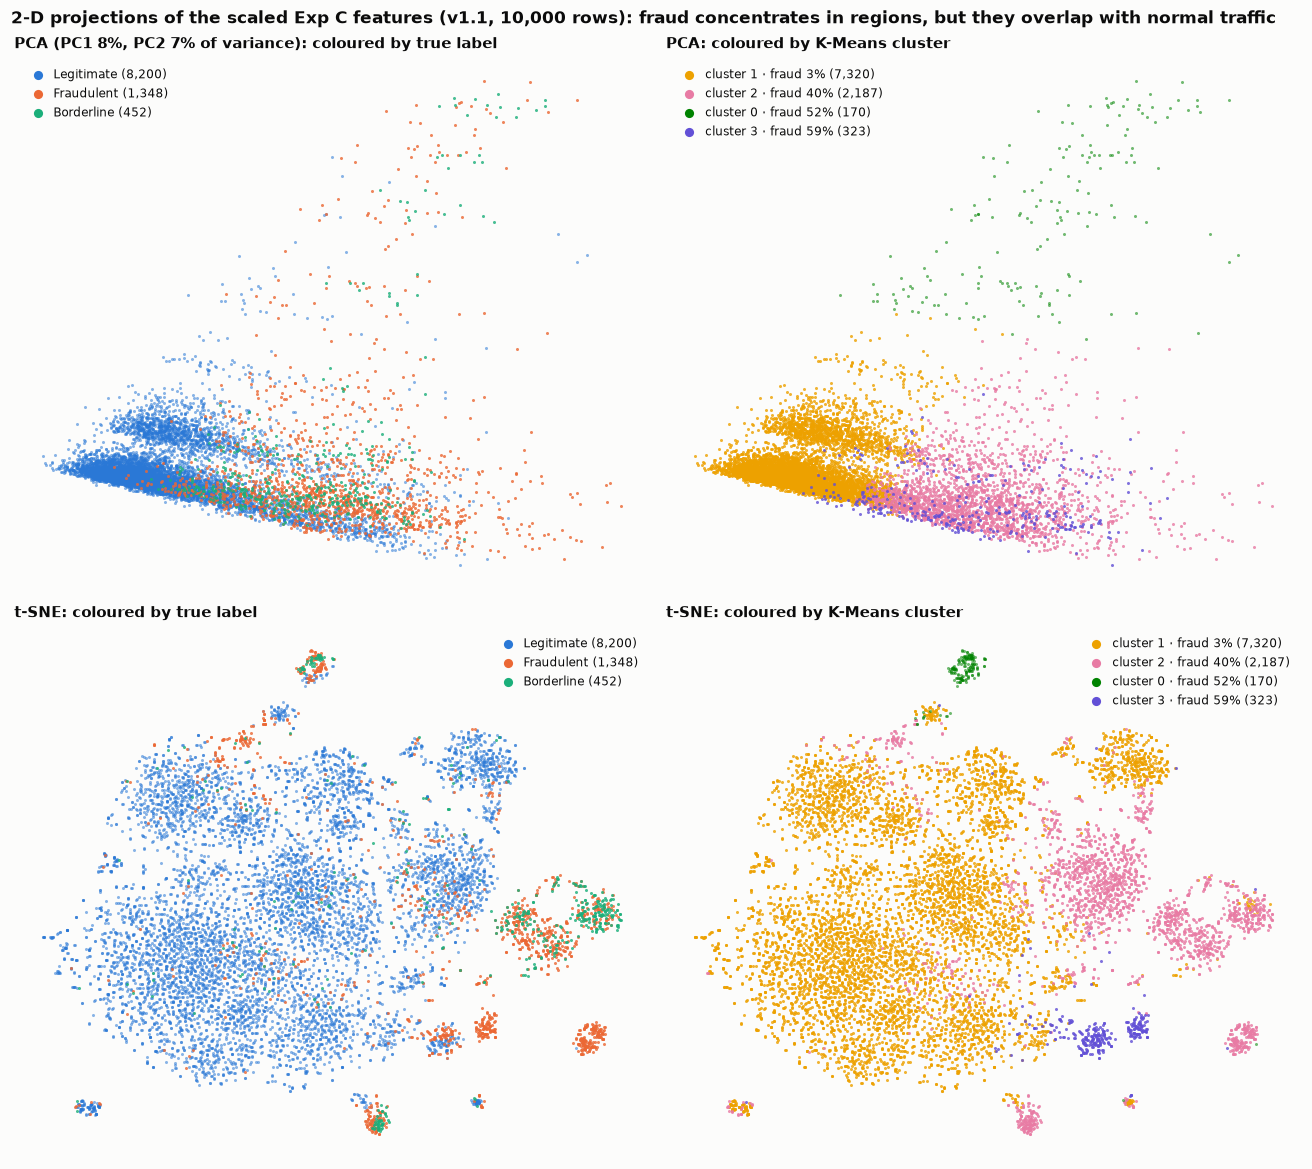

In [4]:
km_labels = cl["main"]["kmeans"].labels_
cfr = pd.Series(m["is_fraud"].to_numpy()).groupby(km_labels).mean().to_dict()
F.fig_embeddings(cl["main"]["proj"], m, km_labels, cfr);

- **PCA** keeps only 15% of the variance in two components (8% + 7%): the 63-dimensional space has no dominant direction. Fraud sits in the long tail to the right but overlaps legitimate rows.
- **t-SNE** (non-linear, perplexity 40) shows the structure much more clearly: the burst cluster (green) and the hub cluster (purple) form tight islands, and several pure-fraud islands appear on the right. These islands are the injected rings and mules. The big normal mass still contains scattered fraud: the **camouflaged** 50% of network fraud and the single-transaction scenarios.
- t-SNE distances between islands are not meaningful; it is a visual aid only and is never used as a model input.

,B,C
min_samples,10.000000,10.000000
eps,4.648307,6.782249
clusters,3.000000,4.000000
noise_rate,0.017200,0.013600
noise_n,172.000000,136.000000
fraud_rate_noise,0.412791,0.551471
fraud_rate_clustered,0.129935,0.129055


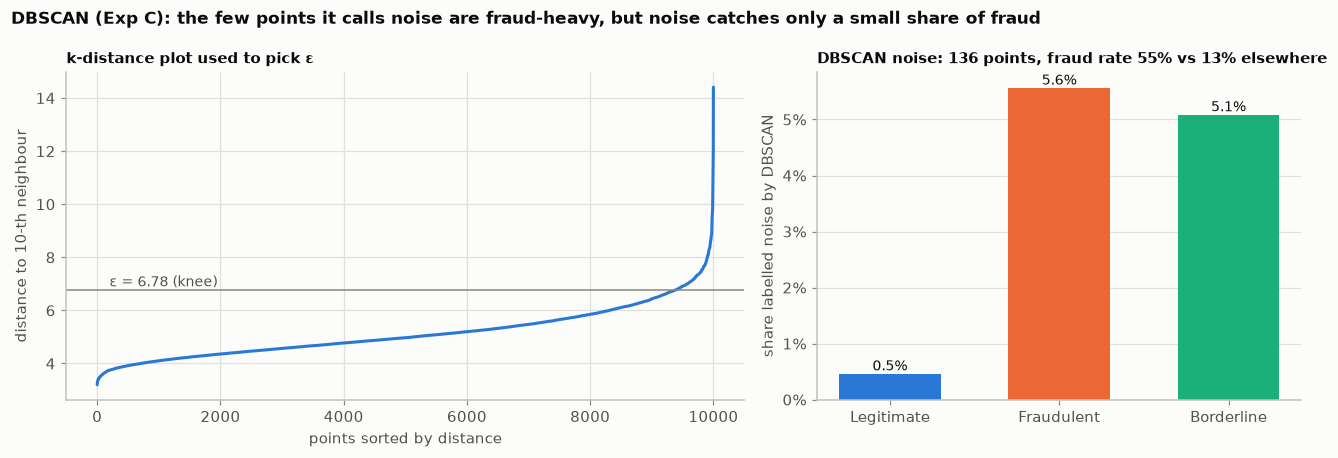

In [5]:
F.fig_dbscan(cl["main"]["kdist"], cl["main"]["eps"], S["C"]["dbscan"]);
display(pd.DataFrame({e: {k: v for k, v in S[e]["dbscan"].items() if not isinstance(v, dict)} for e in ("B", "C")}))

**DBSCAN** (ε = 6.78 from the knee, min_samples = 10) puts almost everything into a few dense clusters and labels **136 points (1.4%) as noise**. Those noise points are **55% fraud** vs 13% elsewhere, so density-based "outlierness" does carry signal. But noise covers only 5.6% of all fraud, and agreement with the labels is weak (ARI 0.13). DBSCAN finds the most extreme points; it is not a general fraud detector. That motivates the dedicated anomaly detectors below.

## 2 · RQ6: anomaly detectors trained only on legitimate rows

,exp,detector,pr_auc,roc_auc,recall_at_1pct_fpr,p95_precision,p95_recall,p95_f1,p99_precision,p99_recall,p95_borderline_flag_rate
0,B,isolation_forest,0.247,0.688,0.037,0.298,0.144,0.195,0.432,0.059,0.111
1,B,ocsvm_nu0.01,0.544,0.806,0.170,0.531,0.670,0.592,0.643,0.615,0.811
2,B,ocsvm_nu0.05,0.546,0.811,0.159,0.548,0.670,0.603,0.649,0.622,0.811
3,B,autoencoder,0.551,0.845,0.133,0.554,0.689,0.614,0.639,0.630,0.800
4,C,isolation_forest,0.358,0.778,0.078,0.407,0.285,0.336,0.521,0.093,0.200
5,C,ocsvm_nu0.01,0.553,0.873,0.048,0.541,0.707,0.613,0.659,0.659,0.800
6,C,ocsvm_nu0.05,0.554,0.874,0.044,0.541,0.715,0.616,0.654,0.644,0.800
7,C,autoencoder,0.543,0.872,0.081,0.547,0.696,0.612,0.639,0.637,0.811


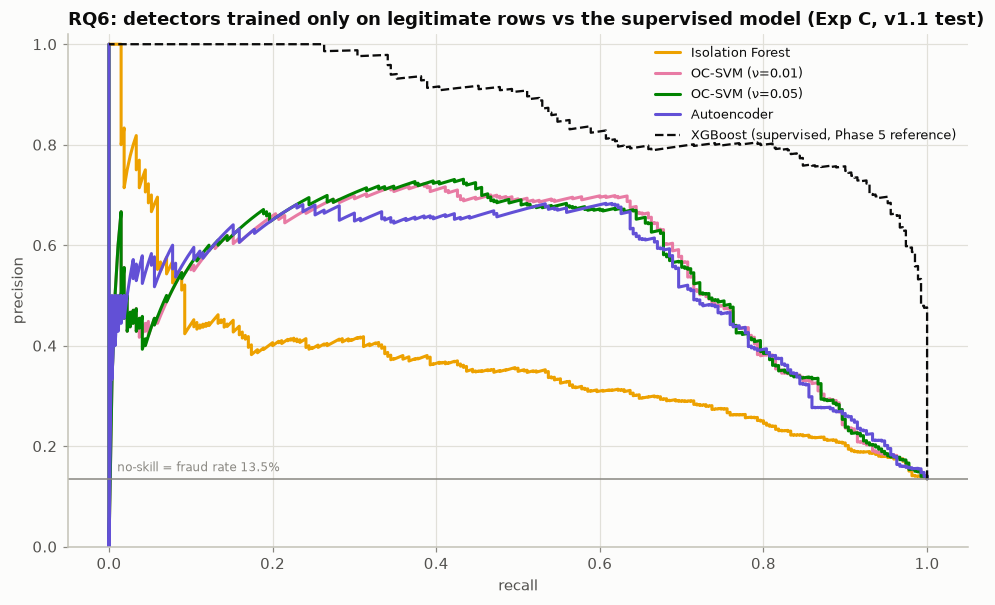

In [6]:
F.fig_detector_pr(an["scores"], an["xgb_proba"], y_te);
cols = ["exp", "detector", "pr_auc", "roc_auc", "recall_at_1pct_fpr", "p95_precision", "p95_recall", "p95_f1",
        "p99_precision", "p99_recall", "p95_borderline_flag_rate"]
display(an["results"][cols].round(3))

| Detector (Exp C, test) | PR-AUC | ROC-AUC | Precision / recall at p95 |
|---|---|---|---|
| One-class SVM (ν = 0.05) | **0.554** | **0.874** | 0.54 / 0.72 |
| One-class SVM (ν = 0.01) | 0.553 | 0.873 | 0.54 / 0.71 |
| Autoencoder | 0.543 | 0.872 | 0.55 / 0.70 |
| Isolation Forest | 0.358 | 0.778 | 0.41 / 0.29 |
| *XGBoost (supervised, Phase 5)* | *0.875* | *0.980* | *0.70 / 0.94* |

- Detectors that never saw a fraud label reach **4× the no-skill PR-AUC** (0.55 vs 0.135) and ROC-AUC ≈ 0.87. The OC-SVM and the Autoencoder are statistically indistinguishable here; the choice of ν barely matters.
- The **supervised model is still far better** (0.875). Labels encode *which* unusual behaviour is fraud, and a novelty detector cannot learn that.
- **Isolation Forest is the weakest.** Its random axis-aligned splits waste effort on the many one-hot and near-constant columns. It benefits most from network features (PR-AUC 0.25 → 0.36, see below).
- Recall at 1% FPR is low for all detectors (≤ 0.17): their very top scores are dominated by unusual-but-legitimate rows (next section).

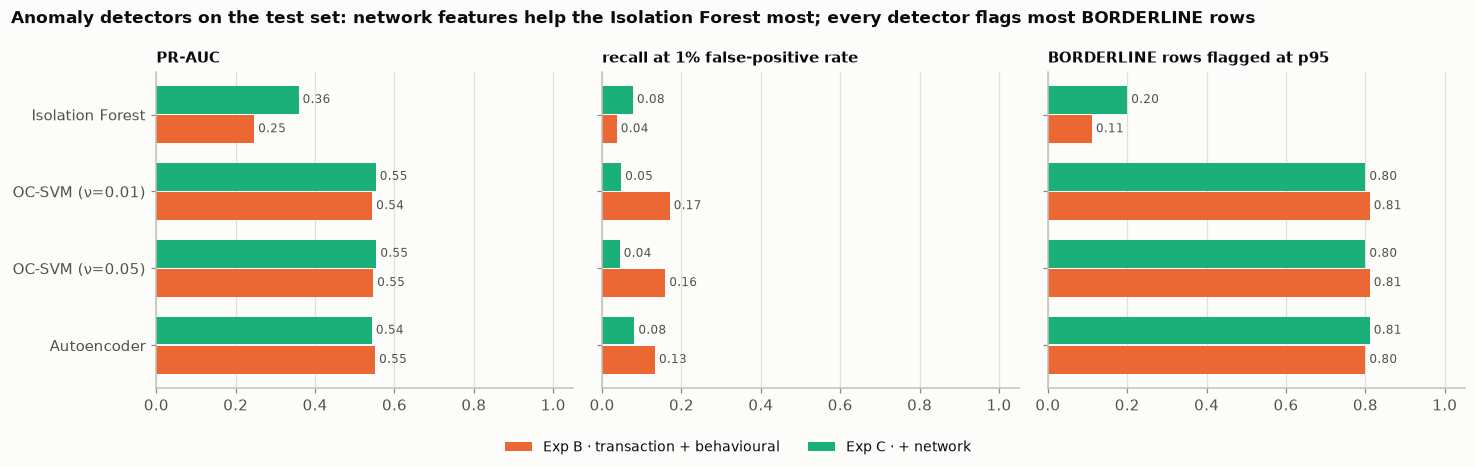

In [7]:
F.fig_detector_bars(an["results"]);

**Exp B vs Exp C:** network features raise IF's PR-AUC by +0.11 and ROC-AUC by +0.09. For OC-SVM and the AE, PR-AUC is flat (≈ 0.55) and ROC-AUC rises (0.81 → 0.87), but recall at 1% FPR *falls*. Adding 19 network columns widens what "normal" looks like, so the very top of the ranking becomes noisier. Compare Phase 5, where the supervised models gained clearly from Exp C: labels let a model use the new columns selectively, and an unsupervised detector has to treat all columns equally.

**Every detector flags ~80% of BORDERLINE rows** (IF: 20%). BORDERLINE rows are *genuinely unusual* (travel, new devices, large first payments), just not fraudulent. This is the central limitation of anomaly detection: **anomalous ≠ fraudulent**.

detector,autoencoder,isolation_forest,ocsvm_nu0.01,ocsvm_nu0.05,xgboost_supervised
scenario,,,,,
S10 impossible travel,1.00,0.06,1.00,1.00,1.00
S11 shared device ip,0.95,0.33,0.95,0.95,1.00
S2 high value spike,0.15,0.05,0.05,0.05,0.80
S3 rapid burst,0.94,0.72,1.00,1.00,0.89
S4 new beneficiary large tx,1.00,0.11,1.00,1.00,0.95
S5 new device suspicious,1.00,0.29,1.00,1.00,1.00
S6 structuring splitting,0.61,0.26,0.78,0.78,0.96
S7 layering network,0.62,0.33,0.62,0.62,0.85
S8 mule pass through,0.42,0.08,0.40,0.40,0.98


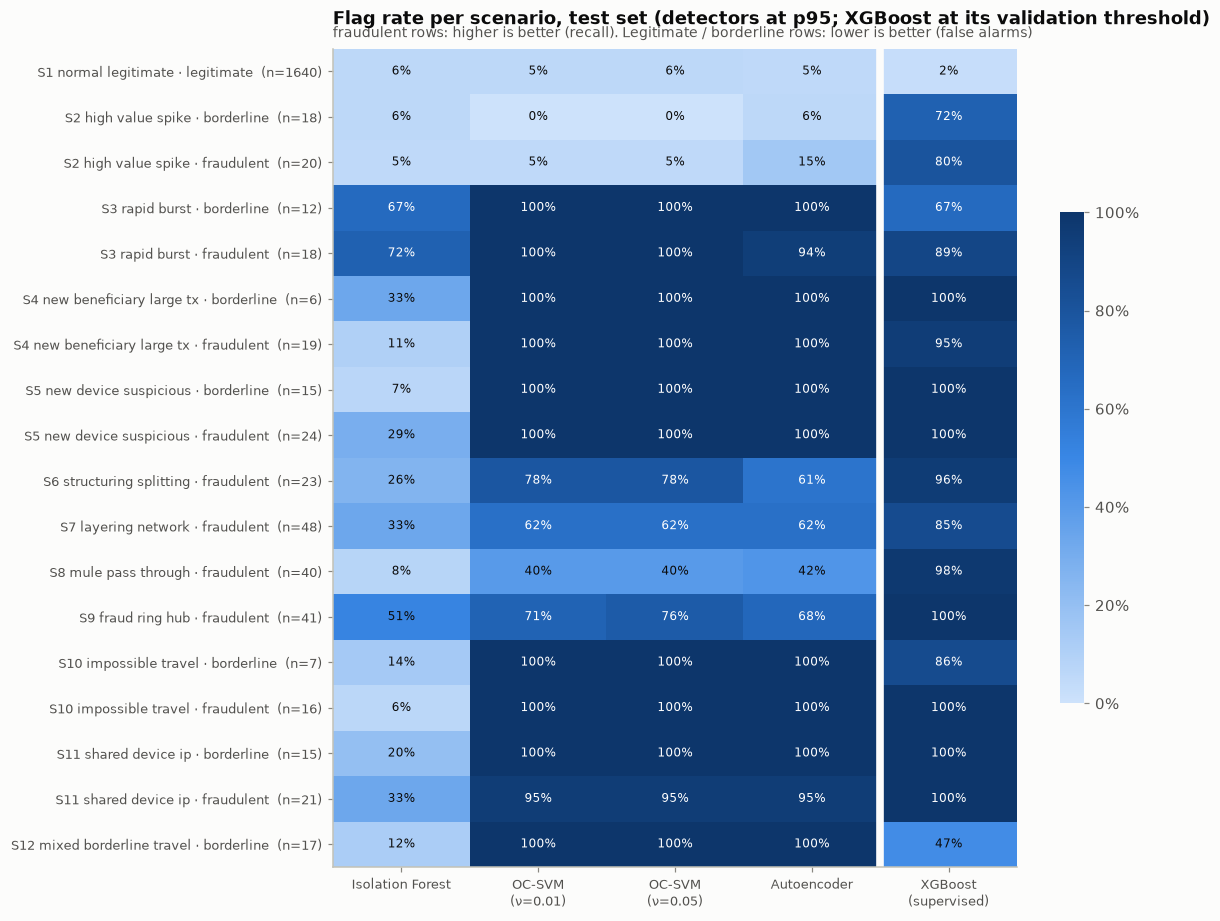

In [8]:
F.fig_scenario_heatmap(an["per_scenario"]);
ps = an["per_scenario"]
display(ps[ps.risk_label == "FRAUDULENT"].pivot_table(index="scenario", columns="detector", values="flag_rate").round(2))

**Per-scenario (RQ6/RQ7):**
- **Caught almost perfectly** (≥ 94% for OC-SVM/AE): S3 rapid burst, S4 new beneficiary + large transaction, S5 new device, S10 impossible travel, S11 shared device/IP. Each is a *single obviously odd transaction*.
- **Partly caught:** S6 structuring (61–78%), S7 layering (62%), S9 ring hub (68–76%), S8 mule pass-through (40–42%). These frauds are built to look normal one transaction at a time; the signal lives in the *network*, which supervised models exploit better (XGBoost 85–100%).
- **Missed:** S2 high-value spike (5–15%). After log-scaling, a large but plausible amount isn't far from normal. XGBoost catches 80% because it learns the *interaction* between amount and the sender's history.
- **False alarms:** about 5% of normal S1 rows (by construction of the p95 threshold), and nearly **all BORDERLINE** scenarios, including S12 mixed borderline travel at 100% (XGBoost: 47%).

{
 "xgb_threshold": 0.09596942365169525,
 "test_frauds": 270,
 "xgb_missed": 16,
 "caught_by": {
  "isolation_forest": 2,
  "ocsvm_nu0.01": 4,
  "ocsvm_nu0.05": 4,
  "autoencoder": 4
 },
 "missed_scenarios": {
  "S7 layering network": 7,
  "S2 high value spike": 4,
  "S3 rapid burst": 2,
  "S6 structuring splitting": 1,
  "S4 new beneficiary large tx": 1,
  "S8 mule pass through": 1
 }
}
Spearman rank correlation with XGBoost probability: {'isolation_forest': 0.51, 'ocsvm_nu0.01': 0.495, 'ocsvm_nu0.05': 0.5, 'autoencoder': 0.492}


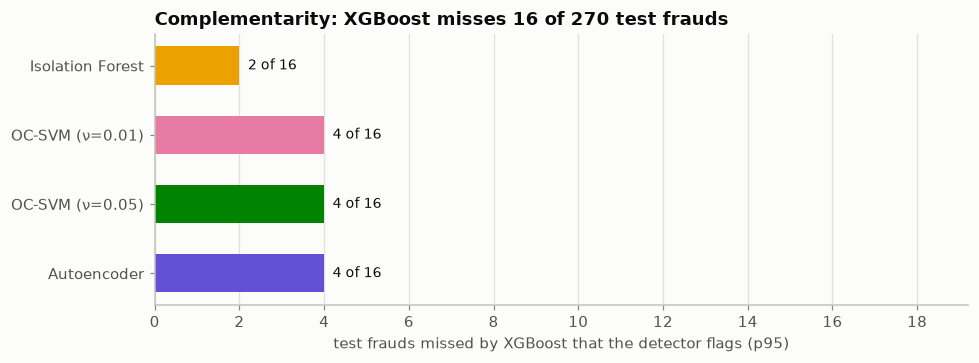

In [9]:
F.fig_complementarity(an["complementarity"]);
print(json.dumps(an["complementarity"], indent=1))
print("Spearman rank correlation with XGBoost probability:", {k: round(v, 3) for k, v in an["spearman_vs_xgb"].items()})

**Complementarity.** XGBoost misses only 16 of 270 test frauds, mostly S7 layering (7) and S2 high-value spikes (4). The OC-SVM and the AE each flag **4 of those 16**, so an anomaly component in the risk score can recover a quarter of the supervised model's misses. The rank correlation between detector scores and the XGBoost probability is only ≈ 0.5, so the two views carry different information. This is the evidence for the Plan §6.6 risk score `w1·P(fraud) + w2·anomaly_pct + w3·graph_risk`. The weights are fitted on validation in Phase 7; `anomaly_pct` comes from `Detector.anomaly_pct` (the percentile in the legit reference distribution).

## 3 · The autoencoder and its ONNX export (CCT link)

epochs: 384 | best val MSE: 0.3495
ONNX parity: {'max_abs_diff_reconstruction': 0.0, 'max_abs_diff_error': 4.76837158203125e-07, 'rows': 2000, 'onnx_bytes': 23752, 'pass': True}


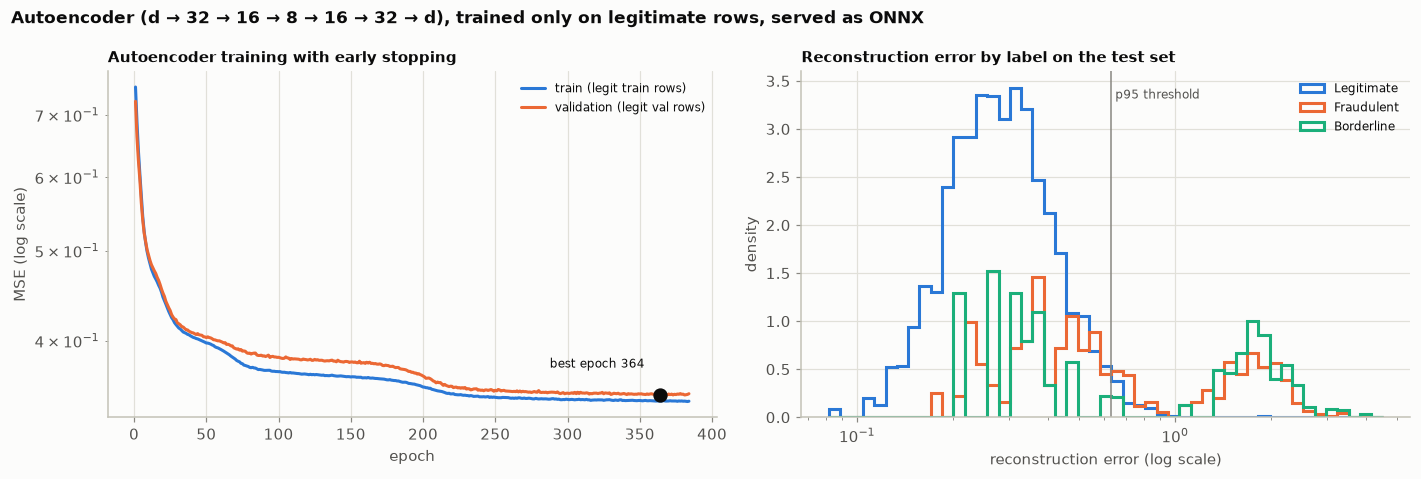

In [10]:
F.fig_autoencoder(an["ae_history"], an["scores"]["autoencoder"], te, an["detectors"]["autoencoder"].threshold(95));
print("epochs:", summary["anomaly"]["ae_epochs"], "| best val MSE:", round(summary["anomaly"]["ae_best_val_loss"], 4))
print("ONNX parity:", summary["onnx_parity"])

In [11]:
# Serving path: reload the artifacts the way ml-service will (onnxruntime only, no torch import)
import joblib
d = config.ARTIFACTS_DIR / "models" / "anomaly"
meta = json.loads((d / "anomaly_meta.json").read_text())
prep = joblib.load(d / "prep_expC.joblib")
onnx_ae = A.OnnxAutoencoder(d / "autoencoder_expC.onnx")
X = prep.transform(te[meta["features"]]).astype(np.float32)
err = onnx_ae.score_samples(X)
ref = np.load(d / "reference_scores_expC.npz")["autoencoder"]
pct = np.searchsorted(ref, err, side="right") / len(ref)
print("ONNX scores == pipeline scores:", np.allclose(err, an["scores"]["autoencoder"], atol=1e-5))
print("anomaly_pct for 5 test rows:", pct[:5].round(3), "| labels:", te["risk_label"].astype(str).head().tolist())
print({p.name: f"{p.stat().st_size/1024:.0f} KB" for p in sorted(d.iterdir())})

ONNX scores == pipeline scores: True
anomaly_pct for 5 test rows: [0.933 0.839 0.749 0.949 1.   ] | labels: ['LEGITIMATE', 'FRAUDULENT', 'LEGITIMATE', 'LEGITIMATE', 'BORDERLINE']
{'anomaly_meta.json': '2 KB', 'autoencoder_expC.onnx': '23 KB', 'autoencoder_expC.pt': '26 KB', 'isolation_forest_expC.joblib': '3540 KB', 'ocsvm_expC.joblib': '158 KB', 'prep_expC.joblib': '9 KB', 'reference_scores_expC.npz': '46 KB'}


- Architecture d → 32 → 16 → 8 → 16 → 32 → d (d = 63), ReLU, MSE, Adam (lr 1e-3, weight decay 1e-5), batch 128. Early stopping (patience 20) on legit validation rows; it stopped at epoch 384 and restored the best weights from epoch 364. Train and validation loss stay close, so there's no overfitting.
- Reconstruction error separates the labels: legit errors peak around 0.3; 70% of fraud rows (and ~80% of BORDERLINE rows) lie beyond the p95 threshold, many at 1–3. The remaining 30% of fraud reconstructs as well as legit data: these are the "normal-looking" frauds (S2, S6 and part of the network scenarios).
- **ONNX export** (legacy TorchScript exporter, opset 17, dynamic batch): **23 KB** file, max |Δ| vs PyTorch = **4.8 × 10⁻⁷** on 2,000 test rows (acceptance: ≤ 1 × 10⁻⁵). The serving container needs only `onnxruntime` (~50 MB), not PyTorch (several hundred MB). That's what makes it fit Render's 512 MB free tier (D-022, Plan §0 #13).

## 4 · PaySim scale track (DMW big-data wrangling + ML at scale)

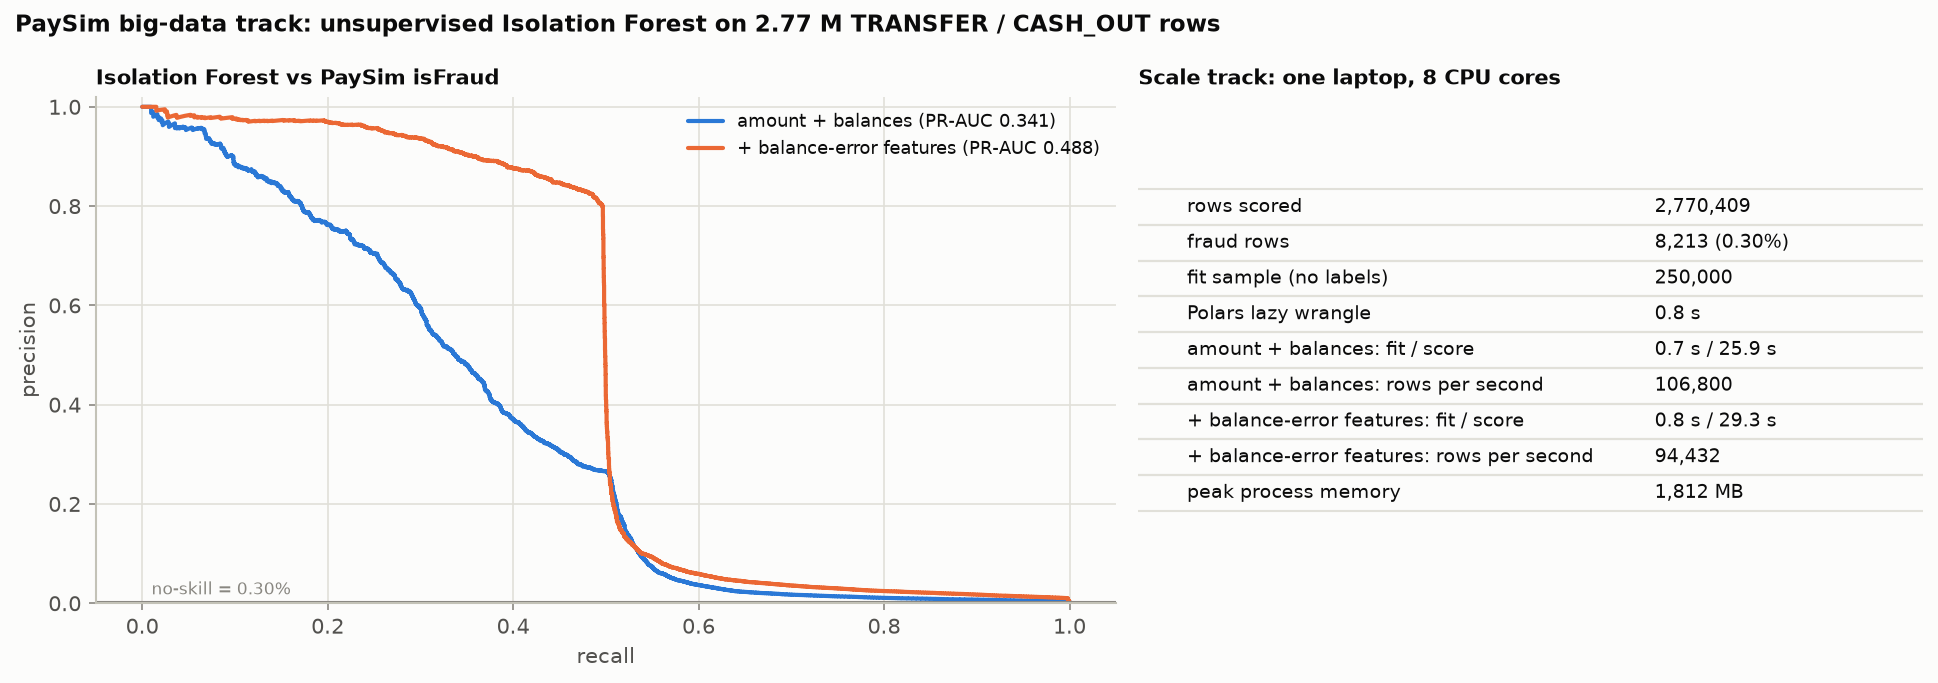

,n_features,fit_seconds,score_seconds,rows_per_second,pr_auc,roc_auc,recall_at_1pct_fpr,p99_precision,p99_recall
raw,7.0,0.67,25.94,106800.0,0.341,0.892,0.525,0.154,0.520
raw+balance_error,9.0,0.82,29.34,94432.0,0.488,0.953,0.521,0.155,0.515


{'rows_scored': 2770409, 'fraud_rows': 8213, 'fraud_rate': 0.002964544224336551, 'fit_sample': 250000, 'wrangle_seconds': 0.84, 'peak_rss_mb': 1811.8}


In [12]:
ps = summary["paysim_if"]
display(Image(filename=str(R / "figures" / "unsup_10_paysim_if.png")))
display(pd.DataFrame(ps["feature_sets"]).T[["n_features", "fit_seconds", "score_seconds", "rows_per_second", "pr_auc", "roc_auc",
                                            "recall_at_1pct_fpr", "p99_precision", "p99_recall"]].round(3))
print({k: v for k, v in ps.items() if k != "feature_sets"})

- **Pipeline:** Polars `scan_csv` (lazy) → keep TRANSFER/CASH_OUT (the only types with fraud) → log-scale amount and balances → add two **balance-error** features (amount not reflected in the sender's or receiver's balance) → streaming collect. 6.36 M rows are reduced to 2.77 M in under a second (file cached), and pandas never sees the raw file.
- **Model:** a fully unsupervised Isolation Forest (200 trees), fitted on a 250 K random sample **without labels** and then used to score all 2.77 M rows at roughly 100 K rows per second on one laptop.
- **Result vs PaySim `isFraud` (0.30% fraud):** PR-AUC **0.34** with raw features → **0.49** with the balance-error features (ROC-AUC 0.89 → 0.95), more than 100× the no-skill PR-AUC. Recall at 1% FPR is about 0.52 in both cases.
- **Wrangling lesson:** two engineered columns moved PR-AUC by +0.15, more than any model choice. The precision cliff at recall ≈ 0.5 shows that about half of PaySim's fraud is trivially anomalous, while the other half scores like normal transactions.
- **Why a separate track:** PaySim has no device, location or beneficiary fields, so a model trained on it can't be applied to the India data (Plan §0 #7). It demonstrates *scale*, not transfer.

## 5 · Answers and hand-off
| RQ | Answer |
|---|---|
| **RQ5** | Partly. With no labels, K-Means (K = 4, Exp C) isolates normal traffic (3% fraud) from three interpretable risk clusters (bursts 52%, fan-in hubs 59%, unusual-amount community flows 40%). ARI 0.47, and reviewing the risk clusters gives 86% recall at 43% precision. Cluster structure is weak overall (silhouette ≤ 0.16), so this is triage, not classification. |
| **RQ6** | Detectors trained only on legitimate rows reach PR-AUC ≈ 0.55 (OC-SVM ≈ AE ≫ IF 0.36) vs 0.875 supervised. They catch single-transaction anomalies (bursts, new device/beneficiary, travel, shared devices) almost perfectly, catch network fraud partly and miss high-value spikes. They flag ~80% of BORDERLINE rows: **anomalous ≠ fraudulent**. They recover 4 of the 16 frauds XGBoost misses. |

**Artifacts for Phase 8 (`ml-service`):** `artifacts/models/anomaly/` (preprocessor, IF, OC-SVM, `autoencoder_expC.onnx`, reference scores for `anomaly_pct`, `anomaly_meta.json` with p95/p99 thresholds) and `artifacts/models/clustering/kmeans_expC.joblib` (for `/cluster`).
**Phase 7** fits the risk-score weights (including `anomaly_pct`) on validation.